# Analyse des données

Ce notebook permet de faire certaines mesures et de tester des hypothèses sur les données afin de déterminer des valeurs clés comme la taille des k-mer et le seuil de nettoyage du jeu de données.

On définit certaines valeurs connues :

+ Taille du génome (sans le complément) : $G = 5.10^6$
+ Longueur d'un k-mer : $k$
+ Longueur d'un read : $L = 250$
+ Nombre de read dans un séquençage : $N$
+ Probabilité d'erreur lors du séquençage : $\varepsilon$
+ La couverture du séquençage par nucléotide : $C = \frac{N\times L}{G}$

In [11]:
# Imports
import numpy as np
import matplotlib.pyplot as plt
from snpDetect import get_count_kmer_in_genome
from collections import defaultdict
import math
from scipy.stats import poisson

In [12]:
DATA_PATH = "data/salmonella-enterica.reads.fna"

G = 5 * 10**6
L = 250
N = 1993167

# Couverture théorique
C = N*L/G
print(f"Couverture théorique par nucléotide : {round(C, 2)}")

Couverture théorique par nucléotide : 99.66


## 1. Déterminer le pourcentage d'erreur observé

Le taux théorique d'erreur pour les séquençages Illumina est de 1%. Cependant, en visualisant les données on constate que celui-ci peut être en réalité bien inférieur. Il s'agit ici d'essayer d'évaluer le pourcentage d'erreur à partir des données ce qui permettra ensuite de faire des meilleures estimations dans les calculs suivants.

On commence donc par calculer la couverture théorique des k-mères sans erreurs qui est donnée par la formule suivante :

$
\lambda_0 = C \times \frac{L-k+1}{L}
$

Puis on relève aussi le maximum local au niveau du premier pic de vrais k-mère qui est la couverture observé ($\lambda_{obs}$).

In [13]:
k_to_test = [15, 19, 25, 31]

data_collected = defaultdict(dict)

for k_t in k_to_test:
    print(f"Collecte des données pour k={k_t}...")
    _, kmer_counts = get_count_kmer_in_genome(k_t, DATA_PATH)

    bins = np.arange(0.5, 300.5, 1)
    counts, bin_edges = np.histogram(kmer_counts, bins=bins, density=False)

    # Maximum local qui correspond au pic des k-mer sans erreurs
    lam_obs = np.argmax(counts[5:]) + 5
    lam_theo = C * (L - k_t + 1) / L
    lam_eff = lam_theo * (1 - 0.01)**k_t

    # Sauvegarder seullement l'histogramme et libérer la mémoire
    data_collected[k_t] = {
        "hist": counts,
        "bins": bin_edges,
        "lam_obs": lam_obs,
        "lam_theo": lam_theo,
        "lam_eff": lam_eff
    }
    del kmer_counts

Collecte des données pour k=15...

--> Comptage des k-mères : salmonella-enterica.reads.fna (k=15, 1 limbe(s), 12 workers)


1/3 : indexation du fichier                 100%|████████████████████████████████████████| 523M/523M o [00:00<00:00]
2/3 : lecture, comptage et fusion des lots  100%|████████████████████████████████████████| 1993167/1993167 reads [00:20<00:00]


        Temps de l'étape (20s), fil principal :
          lecture           |####................................|     2s   12%
          attente workers   |#########################...........|    14s   68%
        En parallèle, dans les autres fils :
          fusion            |################################....|    18s   90%
        En parallèle, dans les 12 workers (38s cumulées, soit 3s chacun) :
          encodage          |######..............................|     6s   15%
          tri               |##############################......|    32s   85%


3/3 : repliage sur le complément inverse    100%|████████████████████████████████████████| 54.0M/54.0M kmers [00:03<00:00]


Terminé : 21578584 k-mères uniques.
Collecte des données pour k=19...

--> Comptage des k-mères : salmonella-enterica.reads.fna (k=19, 1 limbe(s), 12 workers)


...

Terminé : 30851924 k-mères uniques.
Collecte des données pour k=31...

--> Comptage des k-mères : salmonella-enterica.reads.fna (k=31, 1 limbe(s), 12 workers)


1/3 : indexation du fichier                 100%|████████████████████████████████████████| 523M/523M o [00:00<00:00]
2/3 : lecture, comptage et fusion des lots  100%|████████████████████████████████████████| 1993167/1993167 reads [00:22<00:00]


        Temps de l'étape (23s), fil principal :
          lecture           |####................................|     2s   10%
          attente workers   |######################..............|    14s   61%
        En parallèle, dans les autres fils :
          fusion            |#################################...|    21s   92%
        En parallèle, dans les 12 workers (38s cumulées, soit 3s chacun) :
          encodage          |######..............................|     6s   16%
          tri               |##############################......|    32s   84%


3/3 : repliage sur le complément inverse    100%|████████████████████████████████████████| 81.0M/81.0M kmers [00:04<00:00]

Terminé : 35100400 k-mères uniques.


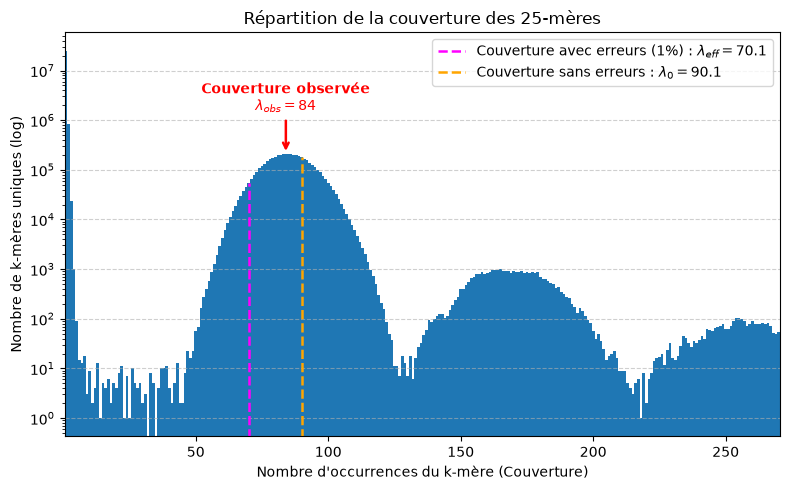

In [14]:
def plot_kmer_coverage(kmer_data, k):
    # Récupération des données
    hist = kmer_data[k]["hist"]
    bins = kmer_data[k]["bins"]
    lam_obs = kmer_data[k]["lam_obs"]
    lam_theo = kmer_data[k]["lam_theo"]
    lam_eff = kmer_data[k]["lam_eff"]

    # Récupère la hauteur de l'histogramme pour une abscisse donnée
    def get_height(val):
        idx = np.searchsorted(bins, val, side="right") - 1
        return hist[idx]

    y_obs = get_height(lam_obs)
    y_theo = get_height(lam_theo)
    y_eff = get_height(lam_eff)

    fig, ax = plt.subplots(figsize=(8, 5))

    # Histogramme
    ax.stairs(hist, bins, fill=True)

    # Lignes verticales tronquées à la hauteur de la courbe
    ax.vlines(
        lam_eff,
        ymin=0,
        ymax=y_eff,
        color="magenta",
        linestyle="--",
        linewidth=1.8,
        label=f"Couverture avec erreurs (1%) : $\\lambda_{{eff}}={round(lam_eff, 1)}$",
    )

    ax.vlines(
        lam_theo,
        ymin=0,
        ymax=y_theo,
        color="orange",
        linestyle="--",
        linewidth=1.8,
        label=f"Couverture sans erreurs : $\\lambda_0={round(lam_theo, 1)}$",
    )

    # Flèche pointant sur le sommet observé
    ax.annotate(
        f"Couverture observée\n$\\lambda_{{obs}} = {lam_obs}$",
        xy=(lam_obs, y_obs),
        xytext=(lam_obs, y_obs * 6),
        arrowprops=dict(facecolor="red", edgecolor="red", arrowstyle="->", lw=1.8),
        ha="center",
        va="bottom",
        color="red",
        fontweight="bold",
    )

    ax.set_title(f"Répartition de la couverture des {k}-mères")
    ax.set_xlabel("Nombre d'occurrences du k-mère (Couverture)")
    ax.set_ylabel("Nombre de k-mères uniques (log)")
    ax.set_yscale("log")
    ax.set_xlim(0.5, 270.5)
    ax.grid(axis="y", linestyle="--", alpha=0.6)

    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

plot_kmer_coverage(data_collected, 25)

Avec les deux valeurs de couvertures on peut déterminer le pourcentage d'erreurs observées sur le jeu de données. Avec Illumina il est normallement aux alentours des 1% mais on constate qu'il est plus faible avec ces données.

$
\varepsilon = 1 - \left(\dfrac{\lambda_{obs}}{\lambda_0}\right)^{1/k}
$

In [15]:
errors = []
tab_line_1 = "k "
tab_line_2 = "e "

for k in k_to_test:
    e = 1 - (data_collected[k]["lam_obs"] /  data_collected[k]["lam_theo"])**(1/k)
    errors.append(e)
    tab_line_1 += f"| {k}    "
    tab_line_2 += f"| {round(e*100, 2)}% "

print(tab_line_1)
print(tab_line_2)
print(f"Moyenne des estimations du taux d'erreurs : {round(np.mean(errors)*100, 2)}%")
print(f"Écart type : {round(np.std(errors), 5)}")

k | 15    | 19    | 25    | 31    
e | 0.37% | 0.26% | 0.28% | 0.3% 
Moyenne des estimations du taux d'erreurs : 0.3%
Écart type : 0.00041


## 2. Trouver un itervalle pour $k$

### 2.1 Trouver la borne supérieure

Pour la borne supérieure, celle-ci va dépendre de la couverture que l'on souhaite avoir. En effet, plus on augmente $k$ plus la couverture des $k$-mères va diminuer. Il faut garantir que la couverture soit assez élevée pour avoir une bonne séparation par rapport aux erreurs de séquençage qui sont au début de l'histogramme.

Si on ne prend pas en compte les erreurs, on a :

$
C \times \frac{L-k+1}{L} \ge C_{min} \\
k \le L (1 - \frac{C_{min}}{C}) + 1
$

Si on prend en compte les erreurs, on a :

$
C \times \frac{L-k+1}{L} \times (1 - \varepsilon)^k
$

que l'on peut résoudre numériquement pour trouver $k_{max}$.

### 2.2 Trouver la borne inférieure

Plus on diminue $k$ plus la chance qu'un $k$-mère ne soit pas unique est élevée. C'est donc cette probabilité que l'on va essayer de minimiser. Pour cela, on se fixe $\delta$ qui est le taux de k-mère non unique que l'on souhaite (ex : 0.01%) et on essaye de déterminer $k_{min}$ tel que $\mathbb{P}(\text{k-mère non unique}) \le \delta$.

$$
\begin{align*} 
\frac{G}{4^{k_{min}}} &\le \delta \\
k_{min} &\ge \log_4\left(\frac{G}{\delta}\right)
\end{align*}
$$

Cette valeur est vraie seulement si on considère que le génome est aléatoire. Or, comme on peut le voir sur l'histogramme précédent, il y a des duplications (les pics à droite) mais on considère qu'on peut les négliger.

Pour C_min=75 : 
	 - sans prendre en compte les erreurs, k_max=63 
	 - avec les erreurs (0.3%), k_max=39 
	 - avec les erreurs (1%), k_max=20

P(k-mer non unique) < 0.001% => k_min=19 ce qui donne 50 k-mères non uniques


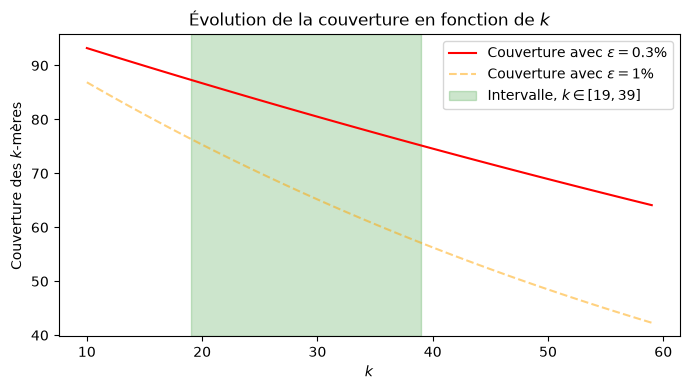

In [16]:
e = 0.003 # On fixe l'erreur à 0.3%
C_min = 75 # Couverture minimum souhaitée
taux_non_unique = 0.00001 # Probabilité max qu'un k-mer soit non unique

x = np.arange(10, 60, 1)
y = []
y2 = []
k_max = -1
k_max_1_percent = -1

for k in x:
    couv = C * ((L-k+1) /  L) * (1-e)**k
    couv_1_percent = C * ((L-k+1) /  L) * (1-0.01)**k
    if couv >= C_min and k > k_max:
        k_max = k
    if couv_1_percent >= C_min and k > k_max_1_percent:
        k_max_1_percent = k
    y.append(couv)
    y2.append(couv_1_percent)

k_max_no_error = round(L * (1 - C_min/C) + 1)

print(f"Pour C_min={C_min} : \n\t - sans prendre en compte les erreurs, k_max={k_max_no_error} \n\t "
      f"- avec les erreurs ({e*100}%), k_max={k_max} \n\t - avec les erreurs (1%), k_max={k_max_1_percent}\n")

k_min = round(math.log(G/taux_non_unique, 4))
nb_kmer_non_unique = round((G-k_min+1)*taux_non_unique)

print(f"P(k-mer non unique) < {taux_non_unique*100}% => k_min={k_min} ce qui donne {nb_kmer_non_unique} k-mères non uniques")

plt.figure(figsize=(7, 4))
plt.plot(x, y, c="red", label=f"Couverture avec $\\epsilon={e*100}$%")
plt.plot(x, y2, linestyle='--', color="orange", alpha=0.5, label=f"Couverture avec $\\epsilon=1$%")
plt.axvspan(k_min, k_max, color="green", alpha=0.2, label=f"Intervalle, $k \\in [{k_min}, {k_max}]$")

plt.title("Évolution de la couverture en fonction de $k$")
plt.xlabel("$k$")
plt.ylabel("Couverture des $k$-mères")
plt.legend()
plt.tight_layout()
plt.show()

# 3. Seuil pour le nettoyage des données

L'objectif est de nettoyer les données, c'est à dire supprimer les k-mères qui sont des erreurs de séquençage pour ensuite détecter les SNP. Il faut donc définir un seuil de couverture minimum à avoir pour considérer que le k-mère est valide.

Dans l'histogramme précédent, les k-mères qui contiennent des erreurs sont ceux qui ont une couverture très faible (1, 2, 3 ou 4). Étant donné que le taux d'erreur est très faible, il est compliqué de modéliser de manière fiable le nombre d'occurence des k-mères erronés. Empiriquement on peut donc décider que le seuil de nettoyage des données ne devra pas se situer en dessous de 8 autrement on risquerai de conserver des erreurs.

Pour déterminer une borne supérieure pour ce seuil on peu regarder le nombre de vrais k-mères que l'on perd. Pour cela on peu modéliser la distribution des vrais k-mères avec une loi de Poisson avec comme paramètre la couverture observée.

In [17]:
K = 31 # Valeur de k choisie à l'étape précédente

# Collecte des données
print(f"Collecte des données pour k={K}...")
_, kmer_counts = get_count_kmer_in_genome(K, DATA_PATH)

bins = np.arange(0.5, 300.5, 1)
counts_density, bin_edges_density = np.histogram(kmer_counts, bins=bins, density=True)
counts, bin_edges = np.histogram(kmer_counts, bins=bins, density=False)

Collecte des données pour k=31...

--> Comptage des k-mères : salmonella-enterica.reads.fna (k=31, 1 limbe(s), 12 workers)


1/3 : indexation du fichier                 100%|████████████████████████████████████████| 523M/523M o [00:00<00:00]
2/3 : lecture, comptage et fusion des lots  100%|████████████████████████████████████████| 1993167/1993167 reads [00:23<00:00]


        Temps de l'étape (24s), fil principal :
          lecture           |####................................|     2s   10%
          attente workers   |######################..............|    15s   62%
        En parallèle, dans les autres fils :
          fusion            |#################################...|    22s   91%
        En parallèle, dans les 12 workers (37s cumulées, soit 3s chacun) :
          encodage          |######..............................|     6s   16%
          tri               |##############################......|    31s   84%


3/3 : repliage sur le complément inverse    100%|████████████████████████████████████████| 81.0M/81.0M kmers [00:05<00:00]

Terminé : 35100400 k-mères uniques.


Lambda:  80
Nombre estimé de vrais k-mères uniques : 4867447
Nombre estimé de k-mères uniques par rapport à la taille du génome : 4999970
T_max = 30
Trouver T_max à partir des quantiles : P(X <= T_max) = 10^-10 => T_max =  30.0


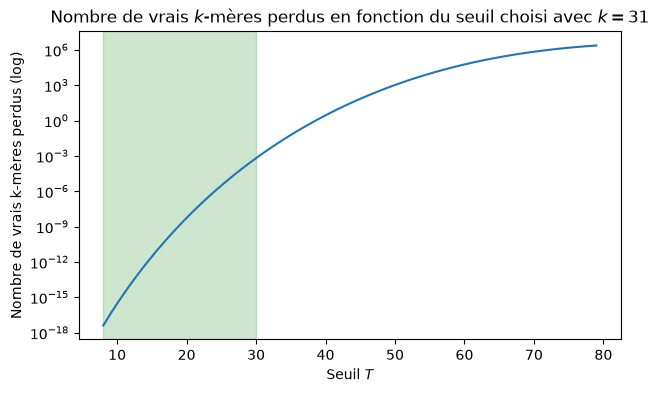

In [18]:
intervalle = (40, 130)

# Loi de Poisson pour modéliser la distribution des vrais k-mères
# Couverture par le calcul
# lam_0 = C * (L - K + 1) / L
# lam = lam_0 *(1-e)**K
# Couverture observée (max local)
lam = np.argmax(counts[intervalle[0]:intervalle[1]+1]) + intervalle[0]
print("Lambda: ", lam)

# Nombre estimé de vrais k-mères uniques
nb_vrai_kmer = np.sum(counts[intervalle[0]:intervalle[1]])
print(f"Nombre estimé de vrais k-mères uniques : {nb_vrai_kmer}\nNombre estimé de k-mères uniques par rapport à la taille du génome : {G-K+1}")

# Nombre de vrais k-mères perdus en fonction du seuil (T)
t = np.arange(8, round(lam))
y = [nb_vrai_kmer*prob for prob in poisson.cdf(t, lam)]
t_max = -1
borne_max_seuil = 10**-3

for i in range(len(t)):
    if y[i] <= borne_max_seuil and t[i] >= t_max:
        t_max = t[i]

print(f"T_max = {t_max}")

print("Trouver T_max à partir des quantiles : P(X <= T_max) = 10^-10 => T_max = ", poisson.ppf(10**-10, lam))

# Graphique
plt.figure(figsize=(7, 4))
plt.plot(t, y)
plt.axvspan(xmax=t_max, xmin=8, color="green", alpha=0.2)
plt.yscale("log")
plt.ylabel("Nombre de vrais k-mères perdus (log)")
plt.xlabel("Seuil $T$")
plt.title(f"Nombre de vrais $k$-mères perdus en fonction du seuil choisi avec $k={K}$")
plt.savefig("figures/final/kmer-perdus.png")
plt.show()